# EDA 04 — Give Me Some Credit (Kaggle 2011)

Nguồn: cuộc thi Kaggle “Give Me Some Credit” — 150.000 khách hàng (tập train).
Nhãn gốc `SeriousDlqin2yrs` (quá hạn ≥ 90 ngày trong 2 năm tới) → `target`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "give_me_some_credit"
df = pd.read_csv(INTERIM / "give_me_some_credit.csv")
df.shape

(150000, 11)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,150000.00
features,10.00
numeric_features,10.00
categorical_features,0.00
duplicate_rows,609.00
cells_missing_pct,2.04
features_with_missing,2.00


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,target
0,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,1
1,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0
2,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0
3,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0
4,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,0


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 150000, 'n_bad': 10026, 'n_good': 139974, 'bad_rate_pct': 6.68, 'imbalance_ratio': 13.96}


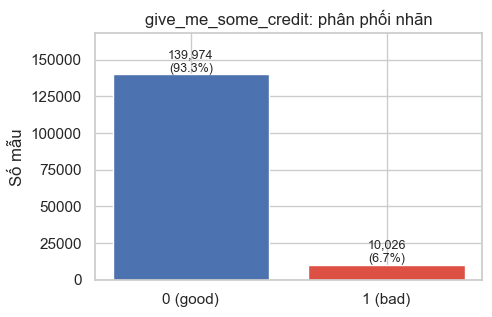

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

,missing_pct
MonthlyIncome,19.82
NumberOfDependents,2.62


,feature,missing_pct,bad_rate_if_missing,bad_rate_if_present,gap
0,NumberOfDependents,2.62,4.56,6.74,-2.18
1,MonthlyIncome,19.82,5.61,6.95,-1.34


## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
RevolvingUtilizationOfUnsecuredLines,125728,0.0,0.154,50708.0,97.631,14544.229,0.509,7.252,0.778
NumberOfTime30-59DaysPastDueNotWorse,16,0.0,0.000,98.0,22.597,522.359,NaN,84.012,0.690
NumberOfTimes90DaysLate,19,0.0,0.000,98.0,23.087,537.721,NaN,94.441,0.657
age,86,0.0,52.000,109.0,0.189,-0.495,0.031,0.001,0.635
NumberOfTime60-89DaysPastDueNotWorse,13,0.0,0.000,98.0,23.332,545.665,NaN,94.931,0.622
MonthlyIncome,13594,0.0,5400.000,3008750.0,114.039,19503.894,4.057,1.359,0.576
NumberOfDependents,13,0.0,0.000,20.0,1.588,3.002,9.129,59.491,0.547
NumberOfOpenCreditLinesAndLoans,58,0.0,8.000,58.0,1.215,3.091,2.653,1.259,0.545
NumberRealEstateLoansOrLines,28,0.0,1.000,54.0,3.482,60.475,0.529,37.459,0.537


Số cột số có |skew| > 2: 7 / 10


## 6. Phân phối theo nhãn

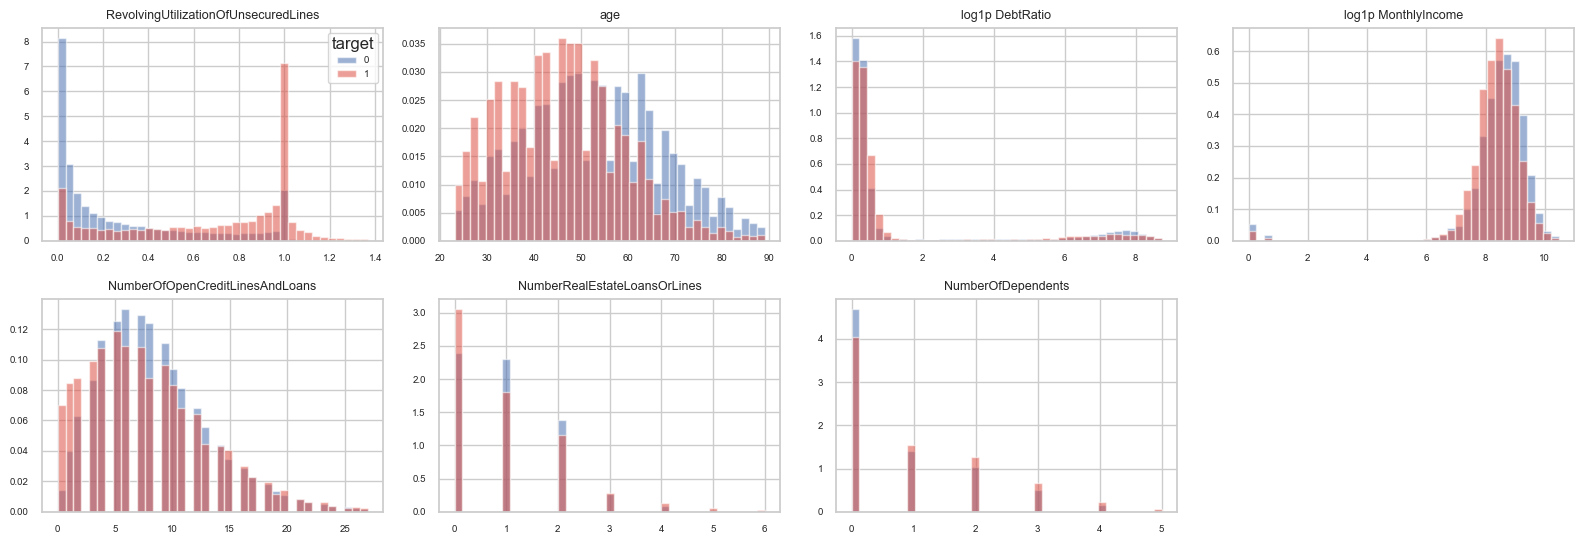

In [7]:
cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
        "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines", "NumberOfDependents"]
clip = df.copy()
clip["RevolvingUtilizationOfUnsecuredLines"] = clip["RevolvingUtilizationOfUnsecuredLines"].clip(upper=1.5)
eda.plot_numeric_by_target(clip, cols, NAME, log=["DebtRatio", "MonthlyIncome"])

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature                              level                                  
NumberOfTime30-59DaysPastDueNotWorse 0           126018      4.00      84.01
                                     1            16033     15.03      10.69
                                     2             4598     26.51       3.07
                                     3             1754     35.23       1.17
                                     4              747     42.57       0.50
                                     5+             581     47.16       0.39
                                     96/98 (mã)     269     54.65       0.18
NumberOfTime60-89DaysPastDueNotWorse 0           142396      5.10      94.93
                                     1             5731     31.01       3.82
                                     2             1118     50.18       0.75
                                     3              318     56.60       0.21
                                     4              105     61.90       0.07
                                     5+              63     63.49       0.04
                                     96/98 (mã)     269     54.65       0.18
NumberOfTimes90DaysLate              0           141662      4.63      94.44
                                     1             5243     33.66       3.50
                                     2             1555     49.90       1.04
                                     3              667     57.72       0.44
                                     4              291     67.01       0.19
                                     5+             313     65.18       0.21
                                     96/98 (mã)     269     54.65       0.18

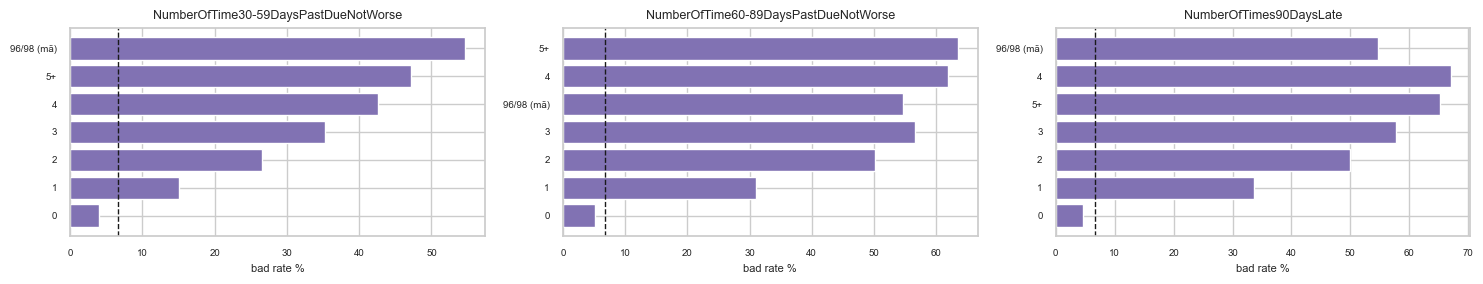

In [8]:
late = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]
capped = df[late + ["target"]].copy()
for c in late:
    capped[c] = capped[c].where(capped[c] < 90, 96).clip(upper=96).map(lambda v: "96/98 (mã)" if v >= 96 else str(min(v, 5)) + ("+" if v >= 5 else ""))
display(eda.categorical_bad_rate(capped, late))
eda.plot_categorical_bad_rate(capped, late, NAME)

## 8. Tương quan

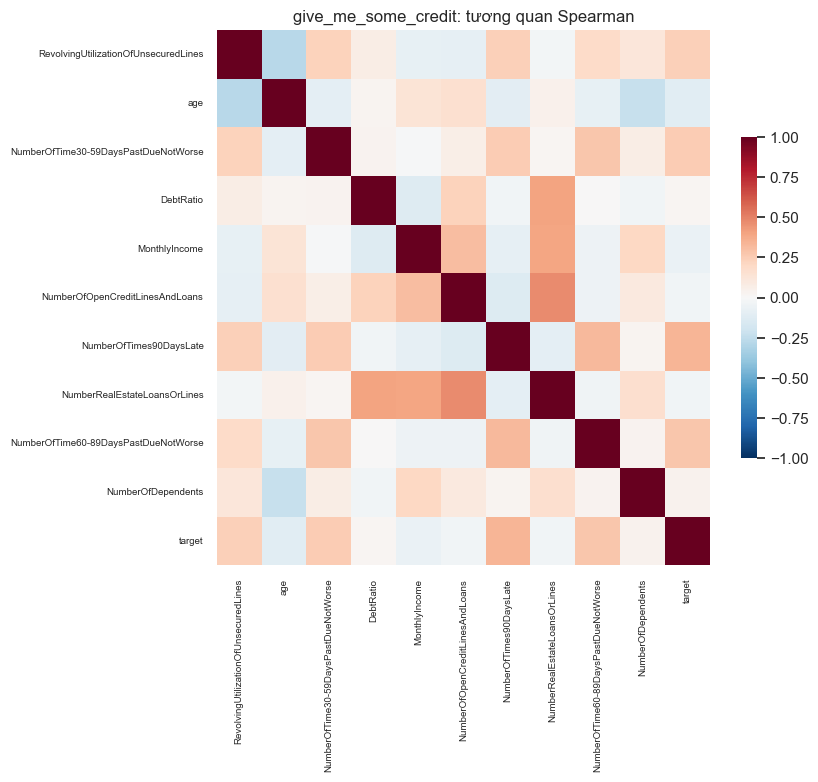

,a,b,spearman


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Giá trị bất thường

In [10]:
late = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]
code = df[late].ge(96).any(axis=1)
print(f"Dòng có mã 96/98 ở các cột trễ hạn: {code.sum()} — bad rate {df.loc[code, 'target'].mean():.1%}")
ru = df["RevolvingUtilizationOfUnsecuredLines"]
print(f"Tỉ lệ sử dụng hạn mức > 1: {(ru > 1).mean():.2%} (max = {ru.max():,.0f}); bad rate {df.loc[ru > 1, 'target'].mean():.1%}")
print(f"age = 0: {(df['age'] == 0).sum()} dòng; age < 21: {(df['age'] < 21).sum()} dòng")
dr = df["DebtRatio"]
print(f"DebtRatio > 1: {(dr > 1).mean():.1%}; median DebtRatio khi MonthlyIncome NaN = {dr[df.MonthlyIncome.isna()].median():,.0f} "
      f"vs khi có thu nhập = {dr[df.MonthlyIncome.notna()].median():.2f}")

Dòng có mã 96/98 ở các cột trễ hạn: 269 — bad rate 54.6%
Tỉ lệ sử dụng hạn mức > 1: 2.21% (max = 50,708); bad rate 37.2%
age = 0: 1 dòng; age < 21: 1 dòng
DebtRatio > 1: 23.4%; median DebtRatio khi MonthlyIncome NaN = 1,159 vs khi có thu nhập = 0.30


In [11]:
X = df.drop(columns="target")
dup = X.duplicated(keep=False)
conflict = df[dup].groupby(list(X.columns), dropna=False)["target"].nunique().gt(1).sum()
print(f"Dòng trùng hoàn toàn: {df.duplicated().sum()}; trùng đặc trưng: {X.duplicated().sum()}; nhóm trùng nhưng khác nhãn: {conflict}")

Dòng trùng hoàn toàn: 609; trùng đặc trưng: 646; nhóm trùng nhưng khác nhãn: 37


## 10. Nhận xét

- **Nhãn: mất cân bằng nặng** — bad rate chỉ ≈ **6,7%** (≈ 14:1). Cần stratified split, đánh giá bằng AUC/PR-AUC, cân nhắc `class_weight`/`scale_pos_weight`.
- **Phân phối lệch cực đoan (bất thường nhất trong nhóm dữ liệu nhỏ):** `RevolvingUtilizationOfUnsecuredLines` (lẽ ra ∈ [0,1]) có max ≈ 50.708, skew ≈ 98; `DebtRatio` skew ≈ 95; `MonthlyIncome` skew ≈ 114. Kurtosis lên tới > 10⁴.
- **Mã đặc biệt 96/98** trong các cột đếm số lần trễ hạn (269 dòng, bad rate ≈ 55%) — không phải số đếm thực mà là mã lỗi/không xác định.
- **Lỗi dữ liệu:** có người `age = 0`; khi `MonthlyIncome` bị thiếu (~20%) thì `DebtRatio` có trung vị ≈ 1.159 thay vì ≈ 0,3 → DebtRatio lúc đó thực chất là tổng nợ tuyệt đối, không phải tỉ lệ.
- **Trùng lặp:** 609 dòng trùng hoàn toàn và 37 nhóm trùng đặc trưng nhưng khác nhãn (nhiễu nhãn).
- Thiếu dữ liệu ở `MonthlyIncome` và `NumberOfDependents` đi kèm bad rate hơi *thấp* hơn trung bình — tính thông tin yếu.

In [12]:
EXTRA = {}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})